# CS4287 Assignment 3 – Deep Reinforcement Learning

## MountainCar-v0 using Deep Q-Networks

This assignment investigates the use of Deep Q-Learning to solve the MountainCar-v0 reinforcement learning environment.

Three approaches will be implemented and compared:

1. Baseline Deep Q-Network (DQN)
2. DQN with Potential-Based Reward Shaping
3. Double Deep Q-Network (Double DQN)

Each approach will be trained using multiple random seeds to investigate the consistency and reliability of the results.

In [1]:
# Install Gymnasium and its classic control environments

!pip install -q "gymnasium[classic-control]"

## 1. MountainCar-v0 Environment

We selected MountainCar-v0 from the Gymnasium Classic Control environments for this assignment.

The environment contains a car positioned between two hills. The main goal is to reach the flag at the top of the right hill. However, the car's engine is not powerful enough to drive directly to the goal. The agent must learn how to build momentum by moving backwards and forwards.

The environment provides two observations: the car's position and velocity. The agent can choose between three actions:

- Push left (0)
- No push (1)
- Push right (2)

The agent receives a reward of -1 for every step. This encourages it to reach the goal in as few steps as possible.

An episode ends when the car reaches the goal or when the maximum of 200 steps is reached.

We chose this environment because the agent must learn a sequence of actions through trial and error rather than being given the correct action for every situation.

In [2]:
# Import the libraries required for the experiments

import gymnasium as gym
import numpy as np
import random
import copy
import os
import json
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from collections import deque


# Select the device used for training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch device:", device)


# Function to initialise all random number generators
def set_global_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print("Libraries imported successfully!")

PyTorch device: cuda
Libraries imported successfully!


### 1.1 Exploring the Environment

Before implementing the learning algorithm, we first examine the MountainCar environment.

We check the observation space, action space and initial state to understand the information available to the agent.

In [3]:
# Create the MountainCar environment
env = gym.make("MountainCar-v0")

# Set the random seed for this initial environment test
state, info = env.reset(seed=42)
env.action_space.seed(42)

# Display information about the environment
print("Environment:", env.spec.id)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", state)

# Close the environment
env.close()

Environment: MountainCar-v0
Observation space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space: Discrete(3)
Initial state: [-0.4452088  0.       ]


### 1.2 Testing Environment Actions

We next test the environment by applying a single action.

This allows us to observe how the car's position and velocity change after an action is performed, as well as the reward received.

In [4]:
# Create a new MountainCar environment
env = gym.make("MountainCar-v0")

# Start an episode
state, info = env.reset(seed=42)

# Select an action: push right
action = 2

# Apply the action
next_state, reward, terminated, truncated, info = env.step(action)

# Display the results
print("Action taken:", action)
print("New position:", next_state[0])
print("New velocity:", next_state[1])
print("Reward received:", reward)
print("Episode finished:", terminated or truncated)

# Close the environment
env.close()

Action taken: 2
New position: -0.44479132
New velocity: 0.00041747934
Reward received: -1.0
Episode finished: False


### 1.3 Initial Data Collection

We collect a small number of experiences by allowing the agent to take 10 random actions in the MountainCar environment.

Each experience contains:

- The current state
- The action taken
- The reward received
- The next state
- Whether the environment reached a terminal state

These experiences demonstrate how information can be collected from the environment. They will later be used to test our experience replay buffer.

Only 10 actions are used here because this is an initial test of the data collection process rather than the actual training process.

In [5]:
# Create the MountainCar environment
env = gym.make("MountainCar-v0")

# Set the seed for reproducible data collection
state, info = env.reset(seed=42)
env.action_space.seed(42)

# Store the collected experiences
experiences = []

# Allow the agent to take 10 random actions
for step in range(10):

    # Select a random action
    action = env.action_space.sample()

    # Apply the action
    next_state, reward, terminated, truncated, info = env.step(action)

    # Check whether the episode has ended
    done = terminated or truncated

    # Store the experience
    experience = (
        state.copy(),
        action,
        reward,
        next_state.copy(),
        terminated
    )

    experiences.append(experience)

    # Display the collected information
    print(
        f"Step {step + 1}: "
        f"Action={action}, "
        f"Reward={reward}, "
        f"Done={done}"
    )

    # Update the current state
    state = next_state

    # Stop if the episode has ended
    if done:
        break

print("\nTotal experiences collected:", len(experiences))

env.close()

Step 1: Action=0, Reward=-1.0, Done=False
Step 2: Action=2, Reward=-1.0, Done=False
Step 3: Action=1, Reward=-1.0, Done=False
Step 4: Action=1, Reward=-1.0, Done=False
Step 5: Action=1, Reward=-1.0, Done=False
Step 6: Action=2, Reward=-1.0, Done=False
Step 7: Action=0, Reward=-1.0, Done=False
Step 8: Action=2, Reward=-1.0, Done=False
Step 9: Action=0, Reward=-1.0, Done=False
Step 10: Action=0, Reward=-1.0, Done=False

Total experiences collected: 10


### 1.4 Experience Replay Buffer

An experience replay buffer stores the agent's previous experiences so that they can be reused during training.

Each experience contains the current state, action, reward, next state and terminal status.

We use a deque with a maximum capacity of 100,000 experiences. When the buffer becomes full, older experiences are automatically removed.

During training, random batches of experiences are sampled from the buffer. This reduces the relationship between consecutive experiences and helps make learning more stable.

In [6]:
# Define the experience replay buffer

class ReplayBuffer:

    def __init__(self, capacity=100000):

        # Store experiences with a maximum capacity
        self.memory = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, terminated):

        # Add a new experience to memory
        self.memory.append(
            (state, action, reward, next_state, terminated)
        )

    def sample(self, batch_size):

        # Randomly sample a batch of experiences
        return random.sample(self.memory, batch_size)

    def __len__(self):

        # Return the number of stored experiences
        return len(self.memory)


# Create a temporary replay buffer to test the implementation
demo_replay_buffer = ReplayBuffer(capacity=100000)

# Add the previously collected experiences
for experience in experiences:
    demo_replay_buffer.add(*experience)

# Sample four experiences
batch = demo_replay_buffer.sample(4)

print("Experiences stored:", len(demo_replay_buffer))
print("Experiences sampled:", len(batch))

Experiences stored: 10
Experiences sampled: 4


### 1.5 DQN Network Architecture

We use a Deep Q-Network (DQN) implemented with PyTorch.

The network receives two inputs representing the car's position and velocity.

It contains two hidden layers, each with 64 neurons. ReLU activation functions are used between the hidden layers to introduce non-linearity.

The output layer contains three neurons, corresponding to the three possible actions in MountainCar:

- Push left
- No push
- Push right

Each output represents the predicted Q-value for an action. The agent uses these values to decide which action is expected to produce the highest future reward.

The network must be trained before its predictions can be used effectively.

In [7]:
# Define the Deep Q-Network

class DQN(nn.Module):

    def __init__(self, state_size=2, action_size=3):

        super(DQN, self).__init__()

        # Define the neural network layers
        self.network = nn.Sequential(

            # Input layer: position and velocity
            nn.Linear(state_size, 64),
            nn.ReLU(),

            # Second hidden layer
            nn.Linear(64, 64),
            nn.ReLU(),

            # Output layer: Q-value for each action
            nn.Linear(64, action_size)
        )

    def forward(self, state):

        # Pass the state through the network
        return self.network(state)


# Set the seed before creating the model
set_global_seed(42)

# Create the DQN model
model = DQN().to(device)

# Display the network architecture
print(model)

# Test the network with a sample state
sample_state = torch.tensor(
    [-0.5, 0.0],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    q_values = model(sample_state)

print("\nPredicted Q-values:", q_values.cpu().numpy())
print("Recommended action:", torch.argmax(q_values).item())

DQN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

Predicted Q-values: [-0.09232986  0.04186955 -0.01413046]
Recommended action: 1


### 1.6 Testing and Integration

Before implementing the training algorithms, we test the integration of the MountainCar environment, DQN network and experience replay buffer.

We use the DQN to predict Q-values for an initial state and select the action with the highest predicted value.

We also check that the replay buffer can successfully store and sample experiences.

At this stage, the DQN has not yet been trained, so its predictions are based on randomly initialised weights.

In [8]:
# Create a new environment for integration testing
test_env = gym.make("MountainCar-v0")

# Start an episode
state, info = test_env.reset(seed=42)

# Convert the state into a PyTorch tensor
state_tensor = torch.tensor(
    state,
    dtype=torch.float32,
    device=device
)

# Predict Q-values using the DQN
with torch.no_grad():
    q_values = model(state_tensor)

# Select the action with the highest Q-value
action = torch.argmax(q_values).item()

# Apply the selected action
next_state, reward, terminated, truncated, info = test_env.step(action)

# Test the replay buffer
sample_batch = demo_replay_buffer.sample(4)

# Display the results
print("State shape:", state_tensor.shape)
print("Q-values shape:", q_values.shape)
print("Selected action:", action)
print("Reward:", reward)
print("Replay buffer size:", len(demo_replay_buffer))
print("Sample batch size:", len(sample_batch))

# Close the environment
test_env.close()

State shape: torch.Size([2])
Q-values shape: torch.Size([3])
Selected action: 1
Reward: -1.0
Replay buffer size: 10
Sample batch size: 4


# 2. Baseline DQN – Training

This section implements and trains the standard Deep Q-Network (DQN) to solve the MountainCar-v0 environment.

The agent learns through trial and error. It stores experiences in a replay buffer and uses these experiences to update its Q-network.

A separate target network is used to help stabilise the learning process. The target network is periodically updated using the weights of the main network.

The results from this baseline will be used as a reference when evaluating the improvements introduced in later experiments.

In [9]:
# Baseline DQN Training Configuration

import random
import numpy as np
import torch
import torch.optim as optim
import copy

# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Select CPU or GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the training environment
baseline_env = gym.make("MountainCar-v0")

# Seed the environment and action space
baseline_env.reset(seed=SEED)
baseline_env.action_space.seed(SEED)

# Create the main DQN
baseline_model = DQN().to(device)

# Create the target DQN
baseline_target_model = DQN().to(device)
baseline_target_model.load_state_dict(baseline_model.state_dict())
baseline_target_model.eval()

# Set up the optimiser
baseline_optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=0.0005
)

# Training hyperparameters
baseline_episodes = 5000
baseline_batch_size = 64
baseline_gamma = 0.99

baseline_epsilon = 1.0
baseline_epsilon_min = 0.05
baseline_epsilon_decay = 0.999

baseline_target_update = 1000

# Create a fresh replay buffer
baseline_replay_buffer = ReplayBuffer(capacity=100000)

# Store training results
baseline_episode_rewards = []
baseline_episode_lengths = []
baseline_episode_losses = []

baseline_training_steps = 0

# Track the best model
baseline_best_reward = float("-inf")
baseline_best_model = None
baseline_best_episode = 0

print("Baseline DQN setup complete.")
print("Device:", device)
print("Training episodes:", baseline_episodes)
print("Replay buffer capacity:", len(baseline_replay_buffer.memory))

Baseline DQN setup complete.
Device: cuda
Training episodes: 5000
Replay buffer capacity: 0


## 2.1 Training the DQN

The DQN learns by sampling batches of past experiences from the replay buffer.

For each experience, the network predicts the Q-value of the action taken. This prediction is compared against a target Q-value calculated using the Bellman equation.

The target network is used to calculate the target Q-values, helping to make training more stable.

The difference between the predicted and target Q-values is measured using the Huber loss function. Backpropagation then updates the main network's weights.

In [10]:
# DQN Learning Function

def train_baseline_model():

    # Wait until there are enough experiences to create a batch
    if len(baseline_replay_buffer) < baseline_batch_size:
        return None

    # Randomly sample experiences from the replay buffer
    batch = baseline_replay_buffer.sample(baseline_batch_size)

    states, actions, rewards, next_states, terminated = zip(*batch)

    # Convert experiences into PyTorch tensors
    states = torch.tensor(
        np.array(states), dtype=torch.float32, device=device
    )

    actions = torch.tensor(
        actions, dtype=torch.long, device=device
    )

    rewards = torch.tensor(
        rewards, dtype=torch.float32, device=device
    )

    next_states = torch.tensor(
        np.array(next_states), dtype=torch.float32, device=device
    )

    terminated = torch.tensor(
        terminated, dtype=torch.float32, device=device
    )

    # Calculate the predicted Q-values for the actions taken
    predicted_q_values = baseline_model(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    # Calculate target Q-values without calculating gradients
    with torch.no_grad():

        next_q_values = baseline_target_model(next_states).max(dim=1)[0]

        target_q_values = (
            rewards
            + baseline_gamma * next_q_values * (1 - terminated)
        )

    # Calculate the loss between predicted and target Q-values
    loss_function = torch.nn.SmoothL1Loss()
    loss = loss_function(predicted_q_values, target_q_values)

    # Update the main network's weights
    baseline_optimizer.zero_grad()
    loss.backward()

    # Limit gradients to help prevent unstable updates
    torch.nn.utils.clip_grad_norm_(
        baseline_model.parameters(), max_norm=10
    )

    baseline_optimizer.step()

    return loss.item()

## 2.2 Baseline DQN Training Loop

The agent is trained over 5,000 episodes.

At the beginning, the agent mostly explores by selecting random actions. As training progresses, the probability of choosing a random action decreases through epsilon decay.

After each action, the agent stores its experience and trains the network using a randomly sampled batch.

The target network is updated periodically, and the model with the best average reward over the previous 50 episodes is saved.

In [11]:
# Baseline DQN Training Loop

for episode in range(baseline_episodes):

    state, info = baseline_env.reset()
    episode_reward = 0
    episode_length = 0
    episode_losses = []

    while True:

        # Epsilon-greedy action selection
        if random.random() < baseline_epsilon:
            action = baseline_env.action_space.sample()
        else:
            state_tensor = torch.tensor(
                state, dtype=torch.float32, device=device
            )

            with torch.no_grad():
                q_values = baseline_model(state_tensor)

            action = torch.argmax(q_values).item()

        # Perform the selected action
        next_state, reward, terminated, truncated, info = baseline_env.step(action)

        # Store the experience (use terminated, not truncated)
        baseline_replay_buffer.add(
            state.copy(),
            action,
            reward,
            next_state.copy(),
            terminated
        )

        # Train the DQN
        loss = train_baseline_model()

        if loss is not None:
            episode_losses.append(loss)

        # Update state and episode statistics
        state = next_state
        episode_reward += reward
        episode_length += 1
        baseline_training_steps += 1

        # Periodically update the target network
        if baseline_training_steps % baseline_target_update == 0:
            baseline_target_model.load_state_dict(
                baseline_model.state_dict()
            )

        # End the episode
        if terminated or truncated:
            break

    # Store episode results
    baseline_episode_rewards.append(episode_reward)
    baseline_episode_lengths.append(episode_length)

    average_loss = (
        np.mean(episode_losses) if episode_losses else 0
    )
    baseline_episode_losses.append(average_loss)

    # Reduce exploration over time
    baseline_epsilon = max(
        baseline_epsilon_min,
        baseline_epsilon * baseline_epsilon_decay
    )

    # Calculate the average reward over the last 50 episodes
    if len(baseline_episode_rewards) >= 50:

        average_reward = np.mean(baseline_episode_rewards[-50:])

        # Save the best-performing model
        if average_reward > baseline_best_reward:
            baseline_best_reward = average_reward
            baseline_best_episode = episode + 1
            baseline_best_model = copy.deepcopy(
                baseline_model.state_dict()
            )

    # Print progress every 50 episodes
    if (episode + 1) % 50 == 0:

        recent_average = np.mean(
            baseline_episode_rewards[-50:]
        )

        print(
            f"Episode {episode + 1}/{baseline_episodes} | "
            f"Average Reward: {recent_average:.2f} | "
            f"Epsilon: {baseline_epsilon:.3f}"
        )

# Restore the best-performing model
if baseline_best_model is not None:
    baseline_model.load_state_dict(baseline_best_model)

# Save the best model
torch.save(
    baseline_model.state_dict(),
    "mountaincar_baseline_best_seed42.pth"
)

print("\nBaseline training complete.")
print("Best 50-episode average:", baseline_best_reward)
print("Best episode:", baseline_best_episode)
print("Final 50-episode average:", np.mean(baseline_episode_rewards[-50:]))

Episode 50/5000 | Average Reward: -200.00 | Epsilon: 0.951
Episode 100/5000 | Average Reward: -200.00 | Epsilon: 0.905
Episode 150/5000 | Average Reward: -200.00 | Epsilon: 0.861
Episode 200/5000 | Average Reward: -200.00 | Epsilon: 0.819
Episode 250/5000 | Average Reward: -200.00 | Epsilon: 0.779
Episode 300/5000 | Average Reward: -200.00 | Epsilon: 0.741
Episode 350/5000 | Average Reward: -200.00 | Epsilon: 0.705
Episode 400/5000 | Average Reward: -200.00 | Epsilon: 0.670
Episode 450/5000 | Average Reward: -200.00 | Epsilon: 0.637
Episode 500/5000 | Average Reward: -200.00 | Epsilon: 0.606
Episode 550/5000 | Average Reward: -200.00 | Epsilon: 0.577
Episode 600/5000 | Average Reward: -200.00 | Epsilon: 0.549
Episode 650/5000 | Average Reward: -200.00 | Epsilon: 0.522
Episode 700/5000 | Average Reward: -200.00 | Epsilon: 0.496
Episode 750/5000 | Average Reward: -200.00 | Epsilon: 0.472
Episode 800/5000 | Average Reward: -200.00 | Epsilon: 0.449
Episode 850/5000 | Average Reward: -200.0

## 2.3 Saving Baseline Training Results

The training results are saved so they can be analysed later without needing to repeat the training process.

The saved data includes episode rewards, episode lengths and training losses. The trained model is also saved separately so it can be loaded for evaluation.

In [12]:
# Save baseline training history

import os

os.makedirs("results/baseline", exist_ok=True)

np.savez(
    "results/baseline/baseline_training_history_seed42.npz",
    episode_rewards=np.array(baseline_episode_rewards),
    episode_lengths=np.array(baseline_episode_lengths),
    episode_losses=np.array(baseline_episode_losses)
)

print("Baseline training history saved.")

Baseline training history saved.


## 2.4 Baseline Training Visualisation

Graphs are used to examine how the agent performs throughout training.

The episode reward graph shows whether the agent is learning to reach the goal in fewer steps. The episode length graph provides another way to observe changes in the agent's performance.

A moving average is included to make the overall learning trend easier to identify.

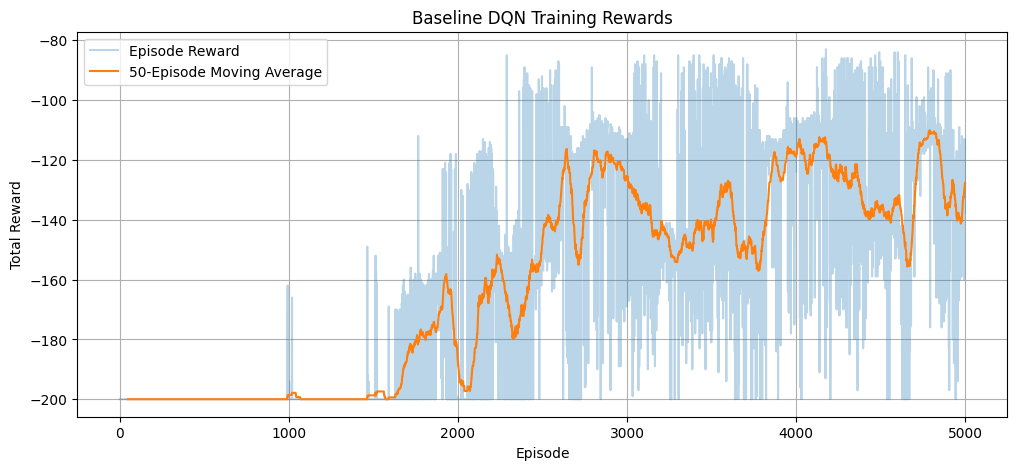

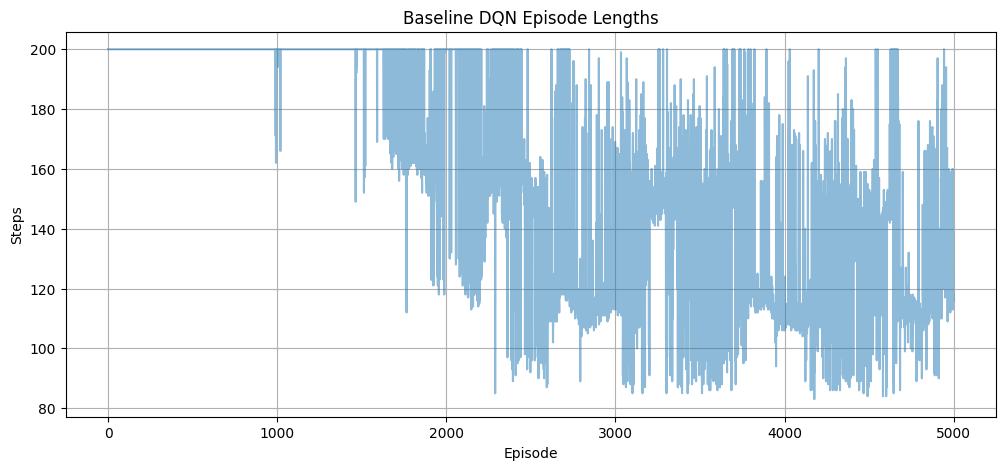

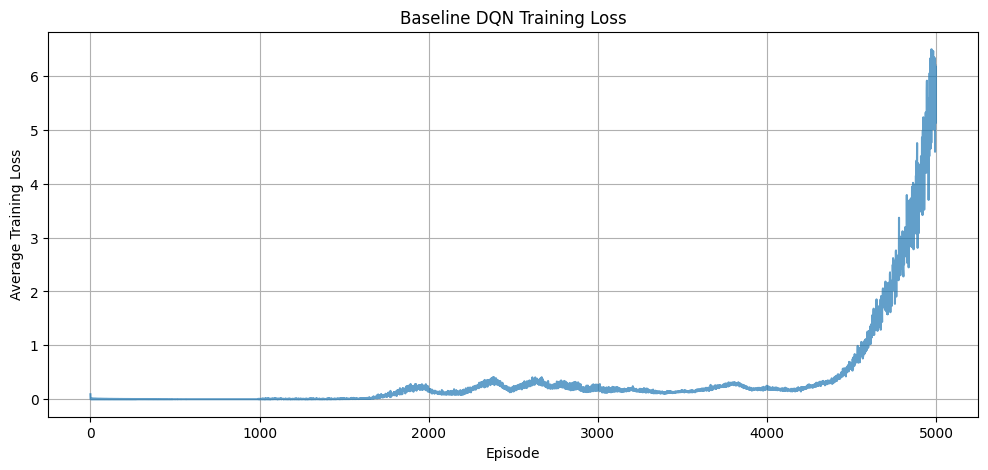

Baseline graphs saved.


In [13]:
# Plot baseline training results

import matplotlib.pyplot as plt

# Calculate 50-episode moving average
window = 50

baseline_moving_average = np.convolve(
    baseline_episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

# Plot episode rewards
plt.figure(figsize=(12, 5))
plt.plot(baseline_episode_rewards, alpha=0.3, label="Episode Reward")
plt.plot(
    range(window - 1, len(baseline_episode_rewards)),
    baseline_moving_average,
    label="50-Episode Moving Average"
)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Baseline DQN Training Rewards")
plt.legend()
plt.grid()
plt.savefig(
    "results/baseline/baseline_training_rewards_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot episode lengths
plt.figure(figsize=(12, 5))
plt.plot(baseline_episode_lengths, alpha=0.5)
plt.xlabel("Episode")
plt.ylabel("Steps")
plt.title("Baseline DQN Episode Lengths")
plt.grid()
plt.savefig(
    "results/baseline/baseline_episode_lengths_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot training loss
plt.figure(figsize=(12, 5))
plt.plot(baseline_episode_losses, alpha=0.7)
plt.xlabel("Episode")
plt.ylabel("Average Training Loss")
plt.title("Baseline DQN Training Loss")
plt.grid()
plt.savefig(
    "results/baseline/baseline_training_loss_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Baseline graphs saved.")

## 2.5 Baseline DQN Evaluation

The trained model is evaluated using a separate environment.

During evaluation, the agent always selects the action with the highest predicted Q-value. Random exploration is disabled.

The evaluation measures average reward, best and worst reward, average episode length and success rate.

An episode is considered successful when the agent reaches the goal position.

In [14]:
# Evaluate the trained baseline DQN

baseline_eval_env = gym.make("MountainCar-v0")

baseline_eval_episodes = 100
baseline_eval_rewards = []
baseline_eval_lengths = []
baseline_successes = 0

# Use fixed evaluation seeds for consistency
baseline_eval_seeds = range(5000, 5100)

baseline_model.eval()

for eval_seed in baseline_eval_seeds:

    state, info = baseline_eval_env.reset(seed=eval_seed)

    total_reward = 0
    steps = 0

    while True:

        state_tensor = torch.tensor(
            state, dtype=torch.float32, device=device
        )

        with torch.no_grad():
            q_values = baseline_model(state_tensor)

        action = torch.argmax(q_values).item()

        next_state, reward, terminated, truncated, info = (
            baseline_eval_env.step(action)
        )

        state = next_state
        total_reward += reward
        steps += 1

        if terminated or truncated:
            break

    baseline_eval_rewards.append(total_reward)
    baseline_eval_lengths.append(steps)

    # MountainCar-v0 goal position is 0.5
    if state[0] >= 0.5:
        baseline_successes += 1

baseline_eval_env.close()

print("Baseline DQN Evaluation")
print("-----------------------")
print("Episodes:", baseline_eval_episodes)
print("Average reward:", np.mean(baseline_eval_rewards))
print("Best reward:", np.max(baseline_eval_rewards))
print("Worst reward:", np.min(baseline_eval_rewards))
print("Average episode length:", np.mean(baseline_eval_lengths))
print("Successful episodes:", baseline_successes)
print("Success rate:", baseline_successes / baseline_eval_episodes * 100, "%")

Baseline DQN Evaluation
-----------------------
Episodes: 100
Average reward: -105.11
Best reward: -83.0
Worst reward: -111.0
Average episode length: 105.11
Successful episodes: 100
Success rate: 100.0 %


## 2.6 Saving Evaluation Results

The evaluation results are saved separately from the training history. This allows the baseline performance to be compared with later approaches using the same evaluation seeds.

In [15]:
# Save baseline evaluation results

np.savez(
    "results/baseline/baseline_evaluation_seed42.npz",
    rewards=np.array(baseline_eval_rewards),
    lengths=np.array(baseline_eval_lengths),
    successes=baseline_successes,
    evaluation_seeds=np.array(list(baseline_eval_seeds))
)

print("Baseline evaluation results saved.")

Baseline evaluation results saved.


# 3. Experiment 1 – Potential-Based Reward Shaping

## 3.1 Introduction

Potential-based reward shaping modifies the original reward signal to provide additional feedback to the agent during learning.

In MountainCar-v0, the agent receives a reward of -1 for every step until it reaches the goal. This can make it difficult for the agent to learn which actions help it make progress.

To address this, a potential function is used to represent the desirability of a state. The change in potential between the current and next state is added to the original reward.

The shaped reward is calculated using:

r' = r + γΦ(s') - Φ(s)

Where:
- r is the original reward.
- γ is the discount factor.
- Φ(s) is the potential of the current state.
- Φ(s') is the potential of the next state.

For this experiment, the car's horizontal position is used as the potential function. Moving towards the goal therefore provides additional positive feedback.

Potential-based reward shaping is used because it can provide denser learning feedback while preserving the optimal policy under the appropriate conditions (Ng, Harada and Russell, 1999).

## 3.2 Reward-Shaping DQN Configuration

A separate DQN is created for this experiment so that it does not interfere with the baseline model.

The same network architecture and training hyperparameters are used to make the comparison fair. The random seed is also set to 42 for this initial run.

A new replay buffer is created to store experiences containing the shaped rewards.

In [16]:
# Reward-Shaping DQN Configuration

# Set random seeds
SHAPING_SEED = 42

random.seed(SHAPING_SEED)
np.random.seed(SHAPING_SEED)
torch.manual_seed(SHAPING_SEED)

# Create a separate MountainCar environment
shaping_env = gym.make("MountainCar-v0")
shaping_env.reset(seed=SHAPING_SEED)
shaping_env.action_space.seed(SHAPING_SEED)

# Create the online DQN
shaping_model = DQN().to(device)

# Create the target DQN
shaping_target_model = DQN().to(device)
shaping_target_model.load_state_dict(shaping_model.state_dict())
shaping_target_model.eval()

# Set up the optimiser
shaping_optimizer = optim.Adam(
    shaping_model.parameters(),
    lr=0.0005
)

# Training hyperparameters
shaping_episodes = 5000
shaping_batch_size = 64
shaping_gamma = 0.99

shaping_epsilon = 1.0
shaping_epsilon_min = 0.05
shaping_epsilon_decay = 0.999

shaping_target_update = 1000

# Create a fresh replay buffer
shaping_replay_buffer = ReplayBuffer(capacity=100000)

# Store training results
shaping_episode_rewards = []
shaping_episode_lengths = []
shaping_episode_losses = []

shaping_training_steps = 0

# Track the best model
shaping_best_reward = float("-inf")
shaping_best_model = None
shaping_best_episode = 0

print("Reward-shaping DQN setup complete.")
print("Device:", device)
print("Training episodes:", shaping_episodes)

Reward-shaping DQN setup complete.
Device: cuda
Training episodes: 5000


## 3.3 Potential Function and Shaped Reward

The potential function uses the car's horizontal position as an estimate of its progress towards the goal.

The shaped reward is calculated by adding the discounted change in potential to the original reward.

When the episode reaches the actual goal, the next state's potential is set to zero. Time-limit truncations are not treated as terminal states because the agent should still be able to bootstrap from those states during learning.

In [17]:
# Potential-Based Reward Shaping Functions

def calculate_potential(state):
    # Use the car's horizontal position as its potential
    return state[0]


def calculate_shaped_reward(state, next_state, terminated):

    current_potential = calculate_potential(state)

    # A true terminal state has zero potential
    if terminated:
        next_potential = 0.0
    else:
        next_potential = calculate_potential(next_state)

    # Original MountainCar reward is -1 per step
    original_reward = -1.0

    # Calculate the potential-based shaped reward
    shaped_reward = (
        original_reward
        + shaping_gamma * next_potential
        - current_potential
    )

    return shaped_reward

## 3.4 Training the Reward-Shaping DQN

The reward-shaping DQN uses the same Q-learning update as the baseline.

The network predicts the Q-value for the action taken, while the target network estimates the maximum future Q-value.

The shaped reward is used in the Bellman target, allowing the additional feedback to influence the network's weight updates.

In [18]:
# Reward-Shaping DQN Learning Function

def train_shaping_model():

    # Check whether enough experiences are available
    if len(shaping_replay_buffer) < shaping_batch_size:
        return None

    # Sample a random batch of experiences
    batch = shaping_replay_buffer.sample(shaping_batch_size)

    states, actions, rewards, next_states, terminated = zip(*batch)

    # Convert experiences into PyTorch tensors
    states = torch.tensor(
        np.array(states), dtype=torch.float32, device=device
    )

    actions = torch.tensor(
        actions, dtype=torch.long, device=device
    )

    rewards = torch.tensor(
        rewards, dtype=torch.float32, device=device
    )

    next_states = torch.tensor(
        np.array(next_states), dtype=torch.float32, device=device
    )

    terminated = torch.tensor(
        terminated, dtype=torch.float32, device=device
    )

    # Predict Q-values for the actions taken
    predicted_q_values = shaping_model(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    # Calculate target Q-values
    with torch.no_grad():

        next_q_values = shaping_target_model(next_states).max(dim=1)[0]

        target_q_values = (
            rewards
            + shaping_gamma * next_q_values * (1 - terminated)
        )

    # Calculate the loss
    loss_function = torch.nn.SmoothL1Loss()
    loss = loss_function(predicted_q_values, target_q_values)

    # Update network weights
    shaping_optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        shaping_model.parameters(), max_norm=10
    )

    shaping_optimizer.step()

    return loss.item()

## 3.5 Reward-Shaping Training Loop

The agent is trained for 5,000 episodes using the same hyperparameters as the baseline.

At each step, the agent selects an action using epsilon-greedy exploration. The original reward is replaced with the shaped reward before the experience is stored in the replay buffer.

The original reward is still recorded separately for performance analysis. This allows the experiment to be compared fairly against the baseline DQN.

The best model is selected using the average original reward over the previous 50 episodes.

In [19]:
# Reward-Shaping DQN Training Loop

for episode in range(shaping_episodes):

    state, info = shaping_env.reset()

    original_episode_reward = 0
    episode_length = 0
    episode_losses = []

    while True:

        # Epsilon-greedy action selection
        if random.random() < shaping_epsilon:
            action = shaping_env.action_space.sample()
        else:
            state_tensor = torch.tensor(
                state, dtype=torch.float32, device=device
            )

            with torch.no_grad():
                q_values = shaping_model(state_tensor)

            action = torch.argmax(q_values).item()

        # Perform the selected action
        next_state, reward, terminated, truncated, info = (
            shaping_env.step(action)
        )

        # Calculate the shaped reward for learning
        shaped_reward = calculate_shaped_reward(
            state, next_state, terminated
        )

        # Store the experience using the shaped reward
        shaping_replay_buffer.add(
            state.copy(),
            action,
            shaped_reward,
            next_state.copy(),
            terminated
        )

        # Train the DQN
        loss = train_shaping_model()

        if loss is not None:
            episode_losses.append(loss)

        # Track the original environment reward
        original_episode_reward += reward
        episode_length += 1

        state = next_state
        shaping_training_steps += 1

        # Periodically update the target network
        if shaping_training_steps % shaping_target_update == 0:
            shaping_target_model.load_state_dict(
                shaping_model.state_dict()
            )

        if terminated or truncated:
            break

    # Save original rewards, not shaped rewards
    shaping_episode_rewards.append(original_episode_reward)
    shaping_episode_lengths.append(episode_length)

    average_loss = (
        np.mean(episode_losses) if episode_losses else 0
    )
    shaping_episode_losses.append(average_loss)

    # Reduce exploration
    shaping_epsilon = max(
        shaping_epsilon_min,
        shaping_epsilon * shaping_epsilon_decay
    )

    # Track the best 50-episode average reward
    if len(shaping_episode_rewards) >= 50:

        average_reward = np.mean(shaping_episode_rewards[-50:])

        if average_reward > shaping_best_reward:
            shaping_best_reward = average_reward
            shaping_best_episode = episode + 1

            shaping_best_model = copy.deepcopy(
                shaping_model.state_dict()
            )

    # Print progress every 50 episodes
    if (episode + 1) % 50 == 0:

        recent_average = np.mean(
            shaping_episode_rewards[-50:]
        )

        print(
            f"Episode {episode + 1}/{shaping_episodes} | "
            f"Average Original Reward: {recent_average:.2f} | "
            f"Epsilon: {shaping_epsilon:.3f}"
        )

# Restore the best-performing model
if shaping_best_model is not None:
    shaping_model.load_state_dict(shaping_best_model)

# Save the best model
os.makedirs("results/reward_shaping", exist_ok=True)

torch.save(
    shaping_model.state_dict(),
    "results/reward_shaping/reward_shaping_best_seed42.pth"
)

print("\nReward-shaping training complete.")
print("Best 50-episode average:", shaping_best_reward)
print("Best episode:", shaping_best_episode)
print(
    "Final 50-episode average:",
    np.mean(shaping_episode_rewards[-50:])
)

Episode 50/5000 | Average Original Reward: -200.00 | Epsilon: 0.951
Episode 100/5000 | Average Original Reward: -200.00 | Epsilon: 0.905
Episode 150/5000 | Average Original Reward: -200.00 | Epsilon: 0.861
Episode 200/5000 | Average Original Reward: -200.00 | Epsilon: 0.819
Episode 250/5000 | Average Original Reward: -200.00 | Epsilon: 0.779
Episode 300/5000 | Average Original Reward: -200.00 | Epsilon: 0.741
Episode 350/5000 | Average Original Reward: -200.00 | Epsilon: 0.705
Episode 400/5000 | Average Original Reward: -200.00 | Epsilon: 0.670
Episode 450/5000 | Average Original Reward: -200.00 | Epsilon: 0.637
Episode 500/5000 | Average Original Reward: -200.00 | Epsilon: 0.606
Episode 550/5000 | Average Original Reward: -200.00 | Epsilon: 0.577
Episode 600/5000 | Average Original Reward: -200.00 | Epsilon: 0.549
Episode 650/5000 | Average Original Reward: -200.00 | Epsilon: 0.522
Episode 700/5000 | Average Original Reward: -198.44 | Epsilon: 0.496
Episode 750/5000 | Average Original

## 3.6 Saving Reward-Shaping Results

The training history is saved separately from the trained model.

This includes the original episode rewards, episode lengths and average training losses. These results will be used to generate graphs and compare the experiment against the baseline.

In [20]:
# Save reward-shaping training history

np.savez(
    "results/reward_shaping/reward_shaping_training_history_seed42.npz",
    episode_rewards=np.array(shaping_episode_rewards),
    episode_lengths=np.array(shaping_episode_lengths),
    episode_losses=np.array(shaping_episode_losses)
)

print("Reward-shaping training history saved.")

Reward-shaping training history saved.


## 3.7 Reward-Shaping Training Visualisation

The training graphs show how the agent's performance changes over time.

The reward graph uses the original MountainCar rewards, allowing direct comparison with the baseline. Episode lengths and training losses are also plotted to provide additional information about the learning process.

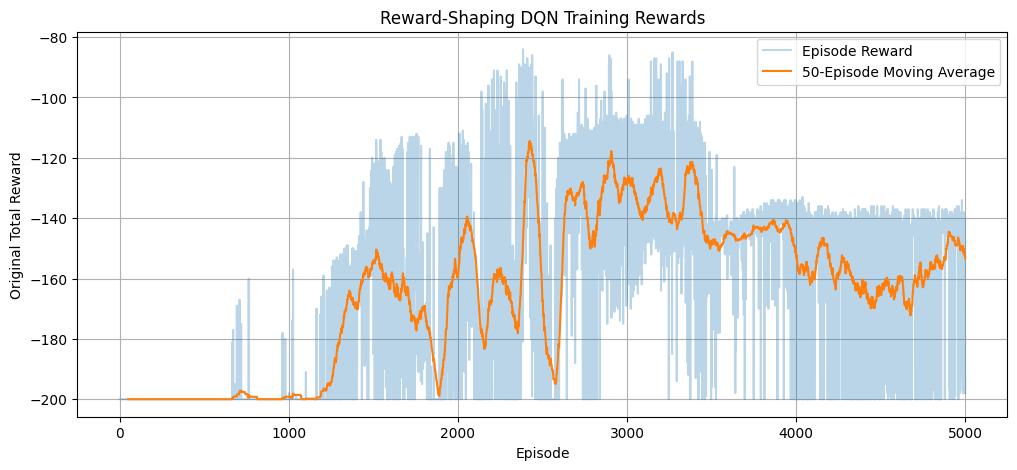

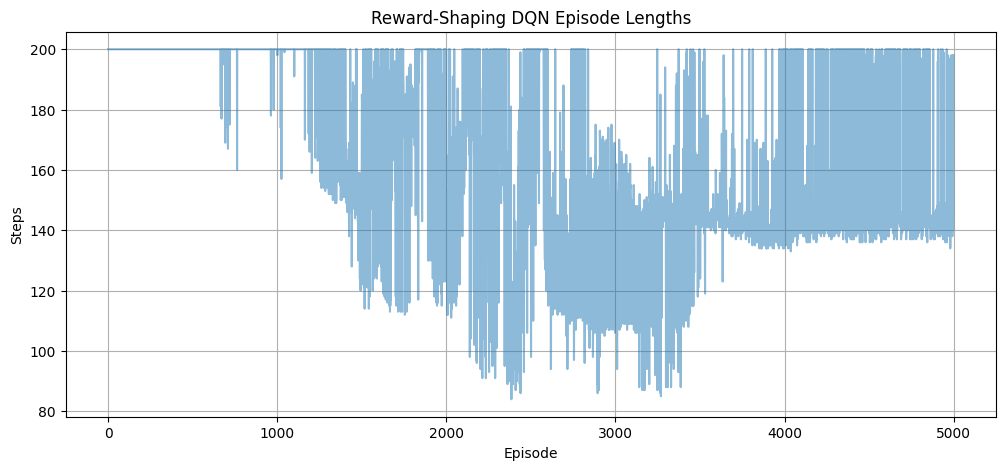

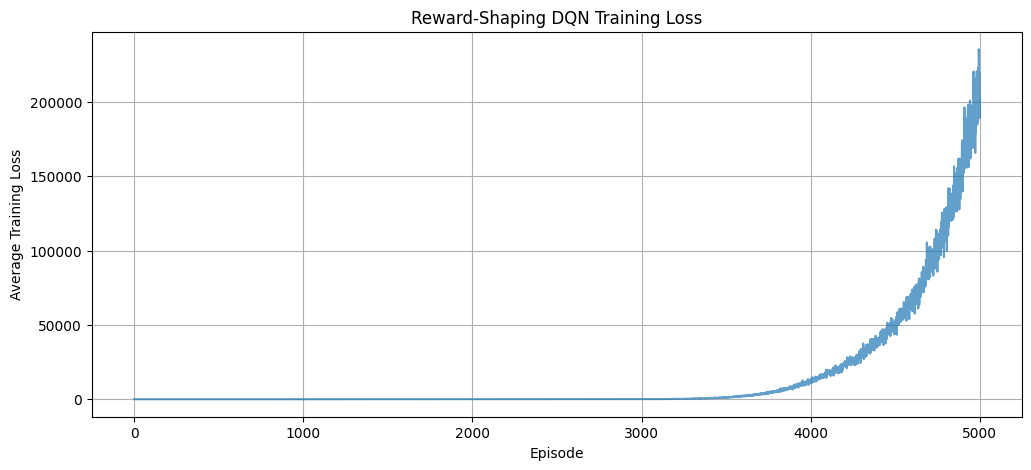

Reward-shaping graphs saved.


In [21]:
# Plot reward-shaping training results

window = 50

shaping_moving_average = np.convolve(
    shaping_episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

# Episode rewards and moving average
plt.figure(figsize=(12, 5))
plt.plot(
    shaping_episode_rewards,
    alpha=0.3,
    label="Episode Reward"
)
plt.plot(
    range(window - 1, len(shaping_episode_rewards)),
    shaping_moving_average,
    label="50-Episode Moving Average"
)
plt.xlabel("Episode")
plt.ylabel("Original Total Reward")
plt.title("Reward-Shaping DQN Training Rewards")
plt.legend()
plt.grid()
plt.savefig(
    "results/reward_shaping/reward_shaping_rewards_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Episode lengths
plt.figure(figsize=(12, 5))
plt.plot(shaping_episode_lengths, alpha=0.5)
plt.xlabel("Episode")
plt.ylabel("Steps")
plt.title("Reward-Shaping DQN Episode Lengths")
plt.grid()
plt.savefig(
    "results/reward_shaping/reward_shaping_lengths_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Training loss
plt.figure(figsize=(12, 5))
plt.plot(shaping_episode_losses, alpha=0.7)
plt.xlabel("Episode")
plt.ylabel("Average Training Loss")
plt.title("Reward-Shaping DQN Training Loss")
plt.grid()
plt.savefig(
    "results/reward_shaping/reward_shaping_loss_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Reward-shaping graphs saved.")

## 3.8 Reward-Shaping Evaluation

The trained reward-shaping model is evaluated with exploration disabled.

The agent always selects the action with the highest predicted Q-value. The original environment reward is used to measure performance rather than the shaped reward.

The same 100 evaluation seeds used for the baseline are used here. This makes the comparison more consistent.

In [22]:
# Evaluate the reward-shaping DQN

shaping_eval_env = gym.make("MountainCar-v0")

shaping_eval_episodes = 100
shaping_eval_rewards = []
shaping_eval_lengths = []
shaping_successes = 0

shaping_eval_seeds = range(5000, 5100)

shaping_model.eval()

for eval_seed in shaping_eval_seeds:

    state, info = shaping_eval_env.reset(seed=eval_seed)

    total_reward = 0
    steps = 0

    while True:

        state_tensor = torch.tensor(
            state, dtype=torch.float32, device=device
        )

        with torch.no_grad():
            q_values = shaping_model(state_tensor)

        action = torch.argmax(q_values).item()

        next_state, reward, terminated, truncated, info = (
            shaping_eval_env.step(action)
        )

        state = next_state
        total_reward += reward
        steps += 1

        if terminated or truncated:
            break

    shaping_eval_rewards.append(total_reward)
    shaping_eval_lengths.append(steps)

    # Check whether the car reached the goal
    if state[0] >= 0.5:
        shaping_successes += 1

shaping_eval_env.close()

print("Reward-Shaping DQN Evaluation")
print("-----------------------------")
print("Episodes:", shaping_eval_episodes)
print("Average reward:", np.mean(shaping_eval_rewards))
print("Best reward:", np.max(shaping_eval_rewards))
print("Worst reward:", np.min(shaping_eval_rewards))
print("Average episode length:", np.mean(shaping_eval_lengths))
print("Successful episodes:", shaping_successes)
print("Success rate:", shaping_successes / shaping_eval_episodes * 100, "%")

Reward-Shaping DQN Evaluation
-----------------------------
Episodes: 100
Average reward: -109.64
Best reward: -83.0
Worst reward: -122.0
Average episode length: 109.64
Successful episodes: 100
Success rate: 100.0 %


## 3.9 Saving Evaluation Results

The evaluation results are saved so that the reward-shaping approach can be compared against the baseline and other experiments without repeating the evaluation.

In [23]:
# Save reward-shaping evaluation results

np.savez(
    "results/reward_shaping/reward_shaping_evaluation_seed42.npz",
    rewards=np.array(shaping_eval_rewards),
    lengths=np.array(shaping_eval_lengths),
    successes=shaping_successes,
    evaluation_seeds=np.array(list(shaping_eval_seeds))
)

print("Reward-shaping evaluation results saved.")

Reward-shaping evaluation results saved.


# 4. Experiment 2 – Double DQN

## 4.1 Introduction

Double DQN is an improvement to the standard Deep Q-Network algorithm that aims to reduce the overestimation of action values.

In a standard DQN, the target network is used to select the action with the highest future Q-value and evaluate that action. This can cause Q-values to become overestimated.

Double DQN separates action selection and action evaluation.

The online network selects the action with the highest predicted Q-value, while the target network evaluates the selected action.

The target is calculated using:

y = r + γ Q_target(s', argmax_a Q_online(s', a))

Where:
- r is the reward received.
- γ is the discount factor.
- Q_online selects the next action.
- Q_target evaluates the selected action.

The goal of this experiment is to determine whether reducing Q-value overestimation improves learning and performance in MountainCar-v0.

## 4.2 Double DQN Configuration

A separate online network and target network are created for the Double DQN experiment.

The same architecture and hyperparameters used by the baseline are retained. This helps ensure that differences in performance are related to the Double DQN learning update rather than changes to the network or training configuration.

A new replay buffer is also created for this experiment.

In [30]:
# Double DQN Configuration

# Set random seeds
DOUBLE_DQN_SEED = 42

random.seed(DOUBLE_DQN_SEED)
np.random.seed(DOUBLE_DQN_SEED)
torch.manual_seed(DOUBLE_DQN_SEED)

# Create a separate MountainCar environment
double_dqn_env = gym.make("MountainCar-v0")
double_dqn_env.reset(seed=DOUBLE_DQN_SEED)
double_dqn_env.action_space.seed(DOUBLE_DQN_SEED)

# Create the online network
double_dqn_model = DQN().to(device)

# Create the target network
double_dqn_target_model = DQN().to(device)
double_dqn_target_model.load_state_dict(
    double_dqn_model.state_dict()
)
double_dqn_target_model.eval()

# Set up the optimiser
double_dqn_optimizer = optim.Adam(
    double_dqn_model.parameters(),
    lr=0.0005
)

# Training hyperparameters
double_dqn_episodes = 5000
double_dqn_batch_size = 64
double_dqn_gamma = 0.99

double_dqn_epsilon = 1.0
double_dqn_epsilon_min = 0.05
double_dqn_epsilon_decay = 0.999

double_dqn_target_update = 1000

# Create a fresh replay buffer
double_dqn_replay_buffer = ReplayBuffer(capacity=100000)

# Store training results
double_dqn_episode_rewards = []
double_dqn_episode_lengths = []
double_dqn_episode_losses = []

double_dqn_training_steps = 0

# Track the best model
double_dqn_best_reward = float("-inf")
double_dqn_best_model = None
double_dqn_best_episode = 0

print("Double DQN setup complete.")
print("Device:", device)
print("Training episodes:", double_dqn_episodes)

Double DQN setup complete.
Device: cuda
Training episodes: 5000


## 4.3 Double DQN Learning Function

The Double DQN learning function follows the same process as the baseline, including replay-buffer sampling, loss calculation and backpropagation.

The main difference is how the next-state Q-value is calculated.

The online network selects the action with the highest Q-value. The target network then evaluates that specific action using gather().

This separates action selection from action evaluation, reducing the potential for overestimated Q-values.

In [31]:
# Double DQN Learning Function

def train_double_dqn():

    # Check whether enough experiences are available
    if len(double_dqn_replay_buffer) < double_dqn_batch_size:
        return None

    # Sample a random batch of experiences
    batch = double_dqn_replay_buffer.sample(double_dqn_batch_size)

    states, actions, rewards, next_states, terminated = zip(*batch)

    # Convert experiences into PyTorch tensors
    states = torch.tensor(
        np.array(states), dtype=torch.float32, device=device
    )

    actions = torch.tensor(
        actions, dtype=torch.long, device=device
    )

    rewards = torch.tensor(
        rewards, dtype=torch.float32, device=device
    )

    next_states = torch.tensor(
        np.array(next_states), dtype=torch.float32, device=device
    )

    terminated = torch.tensor(
        terminated, dtype=torch.float32, device=device
    )

    # Predict Q-values for the actions taken
    predicted_q_values = double_dqn_model(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    # Calculate Double DQN target Q-values
    with torch.no_grad():

        # Online network selects the best next action
        next_actions = double_dqn_model(next_states).argmax(
            dim=1, keepdim=True
        )

        # Target network evaluates the selected action
        next_q_values = double_dqn_target_model(next_states).gather(
            1, next_actions
        ).squeeze(1)

        target_q_values = (
            rewards
            + double_dqn_gamma * next_q_values * (1 - terminated)
        )

    # Calculate the loss
    loss_function = torch.nn.SmoothL1Loss()
    loss = loss_function(predicted_q_values, target_q_values)

    # Update network weights
    double_dqn_optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        double_dqn_model.parameters(), max_norm=10
    )

    double_dqn_optimizer.step()

    return loss.item()

## 4.4 Double DQN Training Loop

The Double DQN is trained for 5,000 episodes using the same hyperparameters as the baseline and reward-shaping approaches.

The agent uses epsilon-greedy exploration, gradually reducing the probability of selecting random actions.

Experiences are stored in the replay buffer and used to update the online network. The target network is periodically updated using the online network's weights.

The best model is selected using the average original reward over the previous 50 episodes.

In [32]:
# Double DQN Training Loop

for episode in range(double_dqn_episodes):

    state, info = double_dqn_env.reset()

    episode_reward = 0
    episode_length = 0
    episode_losses = []

    while True:

        # Epsilon-greedy action selection
        if random.random() < double_dqn_epsilon:
            action = double_dqn_env.action_space.sample()
        else:
            state_tensor = torch.tensor(
                state, dtype=torch.float32, device=device
            )

            with torch.no_grad():
                q_values = double_dqn_model(state_tensor)

            action = torch.argmax(q_values).item()

        # Perform the selected action
        next_state, reward, terminated, truncated, info = (
            double_dqn_env.step(action)
        )

        # Store the experience using the original reward
        double_dqn_replay_buffer.add(
            state.copy(),
            action,
            reward,
            next_state.copy(),
            terminated
        )

        # Train the Double DQN
        loss = train_double_dqn()

        if loss is not None:
            episode_losses.append(loss)

        # Update episode statistics
        episode_reward += reward
        episode_length += 1
        state = next_state

        double_dqn_training_steps += 1

        # Periodically update the target network
        if double_dqn_training_steps % double_dqn_target_update == 0:
            double_dqn_target_model.load_state_dict(
                double_dqn_model.state_dict()
            )

        if terminated or truncated:
            break

    # Store training results
    double_dqn_episode_rewards.append(episode_reward)
    double_dqn_episode_lengths.append(episode_length)

    average_loss = (
        np.mean(episode_losses) if episode_losses else 0
    )
    double_dqn_episode_losses.append(average_loss)

    # Reduce exploration
    double_dqn_epsilon = max(
        double_dqn_epsilon_min,
        double_dqn_epsilon * double_dqn_epsilon_decay
    )

    # Track the best 50-episode average reward
    if len(double_dqn_episode_rewards) >= 50:

        average_reward = np.mean(double_dqn_episode_rewards[-50:])

        if average_reward > double_dqn_best_reward:
            double_dqn_best_reward = average_reward
            double_dqn_best_episode = episode + 1

            double_dqn_best_model = copy.deepcopy(
                double_dqn_model.state_dict()
            )

    # Print progress every 50 episodes
    if (episode + 1) % 50 == 0:

        recent_average = np.mean(
            double_dqn_episode_rewards[-50:]
        )

        print(
            f"Episode {episode + 1}/{double_dqn_episodes} | "
            f"Average Reward: {recent_average:.2f} | "
            f"Epsilon: {double_dqn_epsilon:.3f}"
        )

# Restore the best-performing model
if double_dqn_best_model is not None:
    double_dqn_model.load_state_dict(double_dqn_best_model)

# Save the best model
os.makedirs("results/double_dqn", exist_ok=True)

torch.save(
    double_dqn_model.state_dict(),
    "results/double_dqn/double_dqn_best_seed42.pth"
)

print("\nDouble DQN training complete.")
print("Best 50-episode average:", double_dqn_best_reward)
print("Best episode:", double_dqn_best_episode)
print(
    "Final 50-episode average:",
    np.mean(double_dqn_episode_rewards[-50:])
)

Episode 50/5000 | Average Reward: -200.00 | Epsilon: 0.951
Episode 100/5000 | Average Reward: -200.00 | Epsilon: 0.905
Episode 150/5000 | Average Reward: -200.00 | Epsilon: 0.861
Episode 200/5000 | Average Reward: -200.00 | Epsilon: 0.819
Episode 250/5000 | Average Reward: -200.00 | Epsilon: 0.779
Episode 300/5000 | Average Reward: -200.00 | Epsilon: 0.741
Episode 350/5000 | Average Reward: -200.00 | Epsilon: 0.705
Episode 400/5000 | Average Reward: -200.00 | Epsilon: 0.670
Episode 450/5000 | Average Reward: -200.00 | Epsilon: 0.637
Episode 500/5000 | Average Reward: -200.00 | Epsilon: 0.606
Episode 550/5000 | Average Reward: -199.78 | Epsilon: 0.577
Episode 600/5000 | Average Reward: -199.82 | Epsilon: 0.549
Episode 650/5000 | Average Reward: -199.44 | Epsilon: 0.522
Episode 700/5000 | Average Reward: -199.84 | Epsilon: 0.496
Episode 750/5000 | Average Reward: -196.66 | Epsilon: 0.472
Episode 800/5000 | Average Reward: -197.30 | Epsilon: 0.449
Episode 850/5000 | Average Reward: -200.0

## 4.5 Saving Double DQN Training Results

The training history is saved separately from the model.

Episode rewards, episode lengths and average training losses are stored for later analysis and comparison with the other approaches.

In [33]:
# Save Double DQN training history

np.savez(
    "results/double_dqn/double_dqn_training_history_seed42.npz",
    episode_rewards=np.array(double_dqn_episode_rewards),
    episode_lengths=np.array(double_dqn_episode_lengths),
    episode_losses=np.array(double_dqn_episode_losses)
)

print("Double DQN training history saved.")

Double DQN training history saved.


## 4.6 Double DQN Training Visualisation

The training graphs show how the Double DQN performs throughout training.

Episode rewards are plotted with a 50-episode moving average to make the overall learning trend easier to observe. Episode lengths and training losses are also visualised.

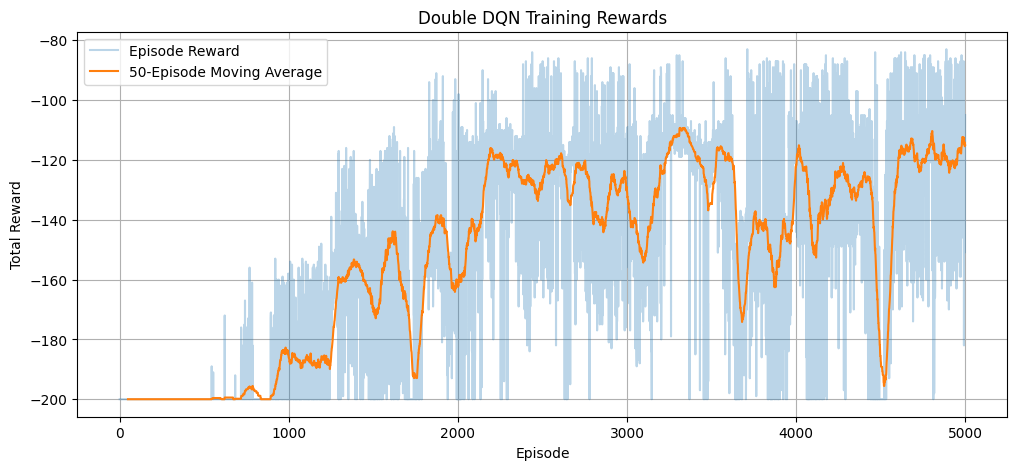

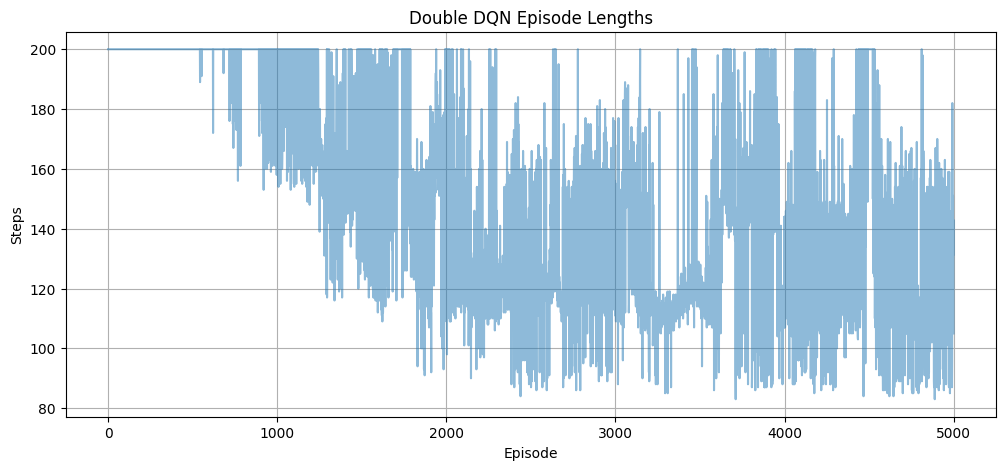

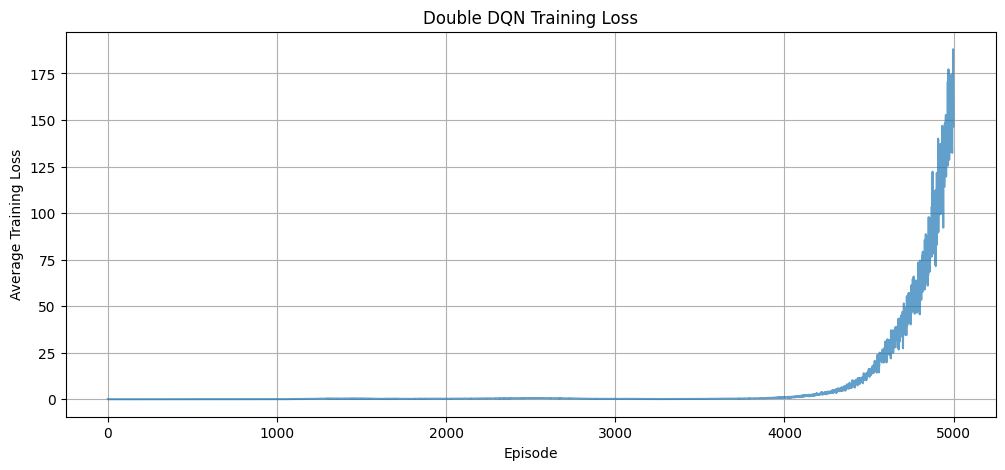

Double DQN graphs saved.


In [34]:
# Plot Double DQN training results

window = 50

double_dqn_moving_average = np.convolve(
    double_dqn_episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

# Episode rewards and moving average
plt.figure(figsize=(12, 5))
plt.plot(
    double_dqn_episode_rewards,
    alpha=0.3,
    label="Episode Reward"
)
plt.plot(
    range(window - 1, len(double_dqn_episode_rewards)),
    double_dqn_moving_average,
    label="50-Episode Moving Average"
)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Double DQN Training Rewards")
plt.legend()
plt.grid()
plt.savefig(
    "results/double_dqn/double_dqn_rewards_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Episode lengths
plt.figure(figsize=(12, 5))
plt.plot(double_dqn_episode_lengths, alpha=0.5)
plt.xlabel("Episode")
plt.ylabel("Steps")
plt.title("Double DQN Episode Lengths")
plt.grid()
plt.savefig(
    "results/double_dqn/double_dqn_lengths_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Training loss
plt.figure(figsize=(12, 5))
plt.plot(double_dqn_episode_losses, alpha=0.7)
plt.xlabel("Episode")
plt.ylabel("Average Training Loss")
plt.title("Double DQN Training Loss")
plt.grid()
plt.savefig(
    "results/double_dqn/double_dqn_loss_seed42.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Double DQN graphs saved.")

## 4.7 Double DQN Evaluation

The trained Double DQN is evaluated with exploration disabled.

The agent always selects the action with the highest predicted Q-value. The same 100 evaluation seeds used for the baseline and reward-shaping approaches are used here.

The evaluation measures average reward, best and worst reward, average episode length and success rate.

In [35]:
# Evaluate the Double DQN

double_dqn_eval_env = gym.make("MountainCar-v0")

double_dqn_eval_episodes = 100
double_dqn_eval_rewards = []
double_dqn_eval_lengths = []
double_dqn_successes = 0

double_dqn_eval_seeds = range(5000, 5100)

double_dqn_model.eval()

for eval_seed in double_dqn_eval_seeds:

    state, info = double_dqn_eval_env.reset(seed=eval_seed)

    total_reward = 0
    steps = 0

    while True:

        state_tensor = torch.tensor(
            state, dtype=torch.float32, device=device
        )

        with torch.no_grad():
            q_values = double_dqn_model(state_tensor)

        action = torch.argmax(q_values).item()

        next_state, reward, terminated, truncated, info = (
            double_dqn_eval_env.step(action)
        )

        state = next_state
        total_reward += reward
        steps += 1

        if terminated or truncated:
            break

    double_dqn_eval_rewards.append(total_reward)
    double_dqn_eval_lengths.append(steps)

    if state[0] >= 0.5:
        double_dqn_successes += 1

double_dqn_eval_env.close()

print("Double DQN Evaluation")
print("---------------------")
print("Episodes:", double_dqn_eval_episodes)
print("Average reward:", np.mean(double_dqn_eval_rewards))
print("Best reward:", np.max(double_dqn_eval_rewards))
print("Worst reward:", np.min(double_dqn_eval_rewards))
print("Average episode length:", np.mean(double_dqn_eval_lengths))
print("Successful episodes:", double_dqn_successes)
print(
    "Success rate:",
    double_dqn_successes / double_dqn_eval_episodes * 100,
    "%"
)

Double DQN Evaluation
---------------------
Episodes: 100
Average reward: -107.38
Best reward: -83.0
Worst reward: -116.0
Average episode length: 107.38
Successful episodes: 100
Success rate: 100.0 %


## 4.8 Saving Double DQN Evaluation Results

The evaluation results are saved separately so that the Double DQN can be compared with the baseline and reward-shaping approaches using the same evaluation conditions.

In [36]:
# Save Double DQN evaluation results

np.savez(
    "results/double_dqn/double_dqn_evaluation_seed42.npz",
    rewards=np.array(double_dqn_eval_rewards),
    lengths=np.array(double_dqn_eval_lengths),
    successes=double_dqn_successes,
    evaluation_seeds=np.array(list(double_dqn_eval_seeds))
)

print("Double DQN evaluation results saved.")

Double DQN evaluation results saved.


# 5. Comparison and Results

## 5.1 Comparing the DQN Approaches

The three approaches are compared using their evaluation results.

The baseline DQN provides a reference point for measuring the performance of the two improvements.

The following metrics are used:

- Average reward: Measures the overall reward obtained across evaluation episodes. Higher (less negative) rewards indicate better performance.
- Best reward: The highest reward obtained in a single episode.
- Worst reward: The lowest reward obtained in a single episode.
- Average episode length: The average number of steps taken to finish an episode.
- Success rate: The percentage of episodes in which the agent reaches the goal.

All approaches are evaluated over the same 100 environment seeds, allowing their performance to be compared under consistent starting conditions.

The results initially shown here use training seed 42. Additional training runs will be used later to investigate consistency.

In [37]:
# Compare evaluation results from all three approaches

import pandas as pd

comparison_results = {
    "Approach": [
        "Baseline DQN",
        "Reward Shaping",
        "Double DQN"
    ],

    "Average Reward": [
        np.mean(baseline_eval_rewards),
        np.mean(shaping_eval_rewards),
        np.mean(double_dqn_eval_rewards)
    ],

    "Best Reward": [
        np.max(baseline_eval_rewards),
        np.max(shaping_eval_rewards),
        np.max(double_dqn_eval_rewards)
    ],

    "Worst Reward": [
        np.min(baseline_eval_rewards),
        np.min(shaping_eval_rewards),
        np.min(double_dqn_eval_rewards)
    ],

    "Average Episode Length": [
        np.mean(baseline_eval_lengths),
        np.mean(shaping_eval_lengths),
        np.mean(double_dqn_eval_lengths)
    ],

    "Successful Episodes": [
        baseline_successes,
        shaping_successes,
        double_dqn_successes
    ],

    "Success Rate (%)": [
        baseline_successes / baseline_eval_episodes * 100,
        shaping_successes / shaping_eval_episodes * 100,
        double_dqn_successes / double_dqn_eval_episodes * 100
    ]
}

comparison_df = pd.DataFrame(comparison_results)

print("DQN Approach Comparison – Training Seed 42")
display(comparison_df.round(2))

DQN Approach Comparison – Training Seed 42


,Approach,Average Reward,Best Reward,Worst Reward,Average Episode Length,Successful Episodes,Success Rate (%)
0,Baseline DQN,-105.11,-83.0,-111.0,105.11,100,100.0
1,Reward Shaping,-109.64,-83.0,-122.0,109.64,100,100.0
2,Double DQN,-107.38,-83.0,-116.0,107.38,100,100.0


## 5.2 Performance Comparison Graphs

Graphs are used to make differences between the three approaches easier to identify.

Average reward and success rate are particularly important when comparing how effectively each approach learns to solve MountainCar-v0.

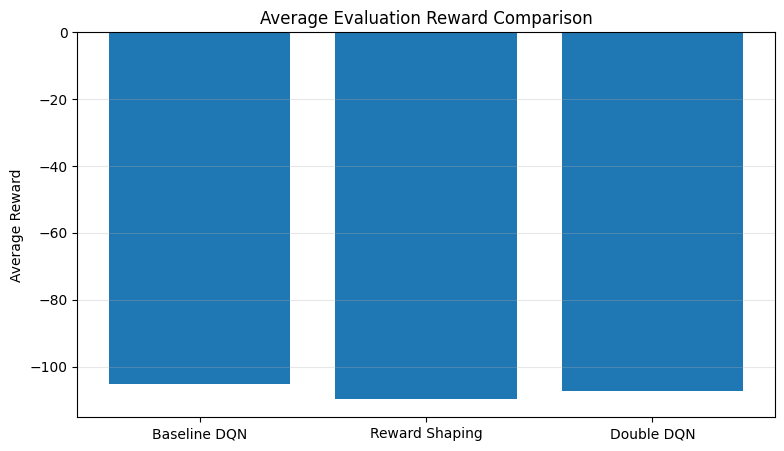

In [38]:
# Compare average evaluation rewards

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Approach"],
    comparison_df["Average Reward"]
)

plt.ylabel("Average Reward")
plt.title("Average Evaluation Reward Comparison")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "results/approach_average_reward_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

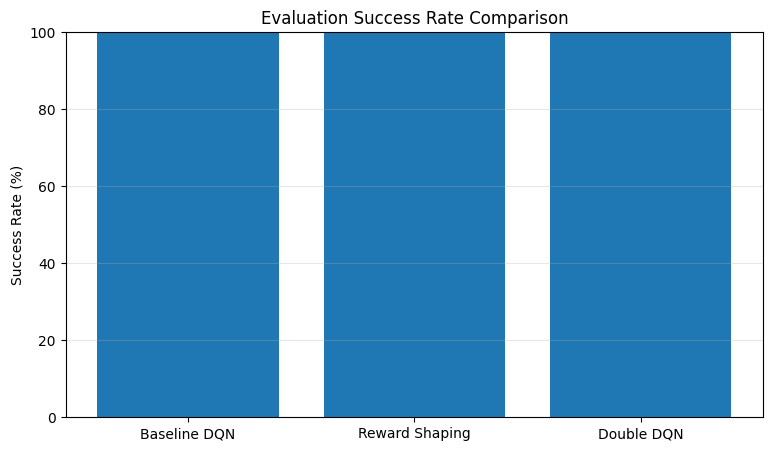

In [39]:
# Compare evaluation success rates

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Approach"],
    comparison_df["Success Rate (%)"]
)

plt.ylabel("Success Rate (%)")
plt.ylim(0, 100)
plt.title("Evaluation Success Rate Comparison")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "results/approach_success_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

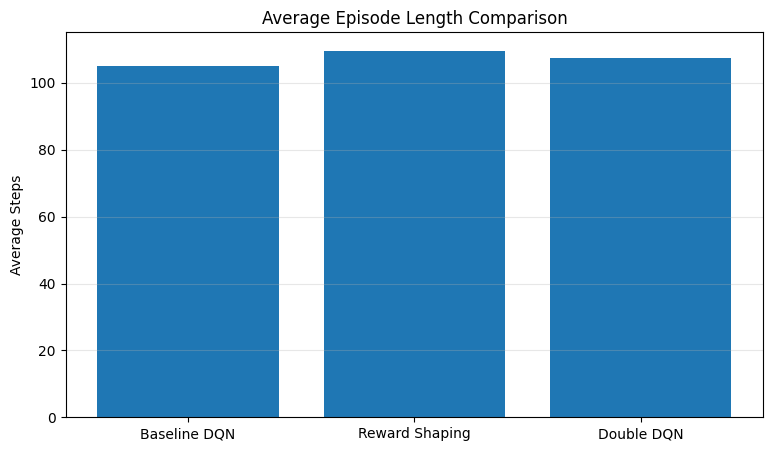

In [40]:
# Compare average episode lengths

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Approach"],
    comparison_df["Average Episode Length"]
)

plt.ylabel("Average Steps")
plt.title("Average Episode Length Comparison")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "results/approach_episode_length_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5.3 Saving Comparison Results

The comparison table is saved as a CSV file so that the results can be reused when preparing the assignment report.

The comparison graphs are also saved as image files.

In [41]:
# Save comparison table

comparison_df.to_csv(
    "results/dqn_approach_comparison_seed42.csv",
    index=False
)

print("Comparison table saved.")

Comparison table saved.
